# IADS5 · TP integrador — Ortelana Textil
### Actividad 14 · Laboratorio del modelo final

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 14 · Laboratorio del modelo final

**Qué se espera:** Partiendo del pipeline candidato, ejecutá GridSearchCV con al menos 3 hiperparámetros y 3 valores por parámetro. Reportá configuración, métrica y evaluación final prevista; prepará borrador de README con reproducción y resultados.

**Evidencia a entregar:** GridSearchCV, análisis de errores y README borrador.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import time

cat_cols = ["Sucursal_ID", "Tela_ID"]
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline_completo(modelo):
    """Numéricas: imputar con la mediana (sin escalar). Categóricas: imputar con la moda y one-hot."""
    preprocesador = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median"))]), num_cols),   # sin escalado: RF es invariante a la escala
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ], verbose_feature_names_out=False)
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])

# Pipeline candidato de la actividad 13
pipe_rf = crear_pipeline_completo(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [3]:
# 14.1 GridSearchCV: 3 hiperparámetros x 3 valores = 27 combinaciones x 5 folds (solo train)
grilla = {"modelo__n_estimators": [100, 300, 500],
          "modelo__max_depth": [None, 10, 20],
          "modelo__min_samples_leaf": [1, 3, 5]}

busqueda = GridSearchCV(pipe_rf, grilla, cv=cv5, scoring="f1_macro", n_jobs=-1, return_train_score=True)
inicio = time.perf_counter()
busqueda.fit(X_train, y_train)
print(f"Tiempo de búsqueda: {time.perf_counter() - inicio:.1f} s")
print("Mejor configuración:", busqueda.best_params_)
print(f"Mejor F1 macro CV (5 folds): {busqueda.best_score_:.4f}")

resultados = pd.DataFrame(busqueda.cv_results_)
columnas = ["param_modelo__n_estimators", "param_modelo__max_depth", "param_modelo__min_samples_leaf",
            "mean_train_score", "mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]
resultados[columnas].sort_values("rank_test_score").head(12).round(4)

Tiempo de búsqueda: 18.7 s
Mejor configuración: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
Mejor F1 macro CV (5 folds): 0.9651


,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,100,None,1,1.0000,0.9651,0.0085,0.3302,1
1,300,None,1,1.0000,0.9632,0.0082,0.9808,2
2,500,None,1,1.0000,0.9632,0.0081,1.7590,3
19,300,20,1,0.9994,0.9535,0.0065,0.9965,4
20,500,20,1,0.9995,0.9527,0.0067,1.6811,5
18,100,20,1,0.9991,0.9511,0.0057,0.3545,6
4,300,None,3,0.9686,0.9102,0.0139,1.0877,7
5,500,None,3,0.9689,0.9096,0.0141,1.5701,8
3,100,None,3,0.9665,0.9067,0.0143,0.5312,9
21,100,20,3,0.9528,0.8990,0.0138,0.3586,10


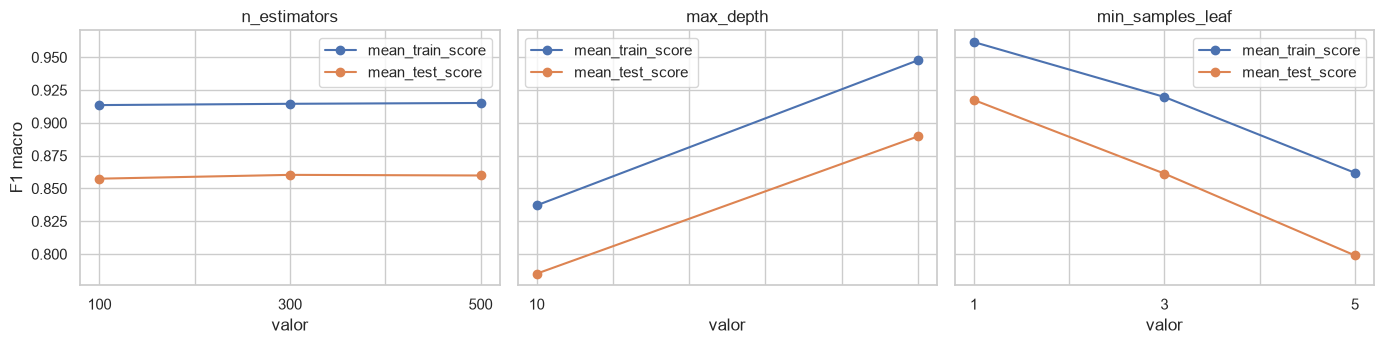

In [4]:
# 14.2 Efecto de cada hiperparámetro (promedio de F1 sobre el resto de la grilla)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, parametro in zip(axes, ["n_estimators", "max_depth", "min_samples_leaf"]):
    columna = "param_modelo__" + parametro
    efecto = resultados.groupby(resultados[columna].astype(str))[["mean_train_score", "mean_test_score"]].mean()
    efecto.plot(marker="o", ax=ax)
    ax.set(title=parametro, xlabel="valor", ylabel="F1 macro")
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           B     0.9757    0.9608    0.9682       586
           C     0.9835    0.9506    0.9667       688
           M     0.9285    0.9967    0.9614       612
           S     0.9726    0.9555    0.9640       742

    accuracy                         0.9650      2628
   macro avg     0.9651    0.9659    0.9651      2628
weighted avg     0.9659    0.9650    0.9650      2628



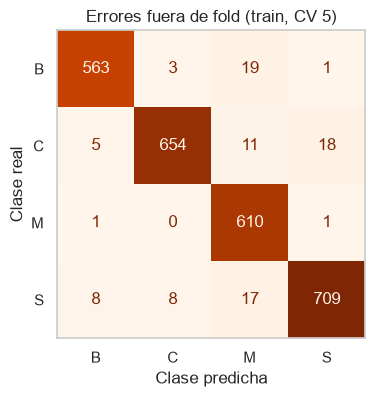

Errores: 92 de 2628 (3.50%)


cantidad
real predicho          
B    M               19
C    S               18
S    M               17
C    M               11
S    B                8
     C                8
C    B                5
B    C                3
     S                1
M    B                1
     S                1

,Metros1 mediana (errores),Metros1 mediana (todos)
B,115.54,284.26
C,396.64,1287.31
M,743.43,153.49
S,270.34,1286.94


In [5]:
# 14.3 Análisis de errores con predicciones fuera de fold (solo train: el test sigue reservado)
mejor_pipe = busqueda.best_estimator_
pred_oof = cross_val_predict(mejor_pipe, X_train, y_train, cv=cv5, n_jobs=-1)
print(classification_report(y_train, pred_oof, digits=4))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_train, pred_oof, ax=ax, cmap="Oranges", colorbar=False)
ax.set(title="Errores fuera de fold (train, CV 5)", xlabel="Clase predicha", ylabel="Clase real")
ax.grid(False)
plt.show()

errores = X_train[y_train != pred_oof].copy()
errores["real"] = y_train[y_train != pred_oof]
errores["predicho"] = pred_oof[y_train != pred_oof]
print(f"Errores: {len(errores)} de {len(X_train)} ({len(errores) / len(X_train):.2%})")
display(errores.groupby(["real", "predicho"]).size().sort_values(ascending=False).rename("cantidad").to_frame())

# ¿Los errores tienen un volumen atípico para su clase real?
pd.DataFrame({"Metros1 mediana (errores)": errores.groupby("real")["Metros1"].median(),
              "Metros1 mediana (todos)": X_train.groupby(y_train)["Metros1"].median()}).round(2)

### Borrador de README

> Borrador preparado en esta actividad. La versión final, con las métricas de test, está en `README.md` (Actividad 15).

**Problema.** Clasificación multiclase de `Format_Reporte` (M mensual, B bimestral, S semestral, C ciclo estacional) a partir de `Sucursal_ID`, `Tela_ID`, `Año`, `Metros1` y `Metros2`. Se excluyen `Metros3`–`Metros12` porque su patrón de faltantes revela la clase. Problema secundario de regresión: `volumen_anual_metros` (suma anual de los metros con dato) a partir de `Sucursal_ID`, `Tela_ID` y `Año`, con `Ridge(alpha=1)`.

**Reproducción.**
1. `python -m pip install -r requirements.txt`
2. Colocar `ventas_historicas_ortelana_argentina.csv` junto a los notebooks.
3. Ejecutar `actividad_01.ipynb` (genera `particion_train_test.csv`) y luego las demás actividades (semilla 42).

**Resultados de selección (solo train, sin test).**
- Modelo candidato: pipeline (imputación + one-hot, sin escalado porque RF es invariante a la escala) + `RandomForestClassifier`.
- GridSearchCV (5 folds, F1 macro): `n_estimators=100`, `max_depth=None`, `min_samples_leaf=1` → F1 macro CV = 0,9651.
- Evaluación final prevista: un único cálculo de F1 macro, accuracy y matriz de confusión sobre el 20% de test (Actividad 15).

**Pendiente.** Métricas finales de test, serialización (`models/modelo_productivo.joblib`) y script `src/predecir.py`.

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **GridSearchCV:** sobre el pipeline candidato completo (el preprocesamiento queda dentro de cada fold), con **3 hiperparámetros × 3 valores**:
  - `n_estimators` ∈ {100, 300, 500}, para la estabilidad del promedio;
  - `max_depth` ∈ {None, 10, 20}, para la complejidad de cada árbol;
  - `min_samples_leaf` ∈ {1, 3, 5}, como regularización.
- **Costo:** son 27 combinaciones × 5 folds estratificados = 135 ajustes. Usamos 5 folds en lugar de 10 para controlar el costo, con F1 macro como scoring.
- **Análisis de errores:** con `cross_val_predict` sobre train, para **no tocar el test**.
- **README:** el borrador está en una celda de texto al final de esta actividad; la versión final es `README.md` (Actividad 15).

**Interpretación de los resultados:**
- **Mejor configuración:** `n_estimators=100`, `max_depth=None` y `min_samples_leaf=1`, con F1 macro CV = **0,9651 ± 0,0085**. Es la configuración por defecto: 300 o 500 árboles dan prácticamente lo mismo (0,963) con 3 a 7 veces más tiempo de ajuste.
- **Efecto de cada hiperparámetro:** el más influyente es `min_samples_leaf`, que con 3 baja el F1 a ~0,91. Limitar `max_depth` a 20 lo baja a ~0,95.
- **Por qué cualquier restricción empeora:** con este dataset, los árboles necesitan llegar a hojas muy específicas para aislar cada par (Sucursal, Tela). Es la misma memorización que muestra la CV agrupada de la Actividad 13: la búsqueda optimiza el escenario de pares conocidos.
- **Evaluación final prevista:** el test se usará una sola vez, en la Actividad 15, con F1 macro, accuracy, reporte por clase y matriz de confusión.
- **Errores fuera de fold:** 92 de 2.628 (3,5%).
  - Las confusiones más frecuentes son B→M (19), C→S (18), S→M (17) y C→M (11).
  - M tiene recall 0,997 pero precision 0,93, porque "atrae" registros de otras clases.
  - Los errores ocurren cuando el volumen es atípico para la clase real. Por ejemplo, los C y S mal clasificados tienen una mediana de `Metros1` de 397 m y 270 m, contra ~1.287 m de su clase. Los M mal clasificados tienen 743 m, contra 153 m.

**Pregunta de análisis:** ¿Qué errores de negocio son más costosos? ¿Qué métrica deberías optimizar?
- **Errores más costosos:** a falta de una definición de negocio, los más costosos son los que **cruzan la granularidad del reporte**: predecir un formato de baja frecuencia (semestral o ciclo estacional, 2 períodos) cuando es de alta frecuencia (mensual o bimestral, 6–12 períodos), o al revés. Implican esperar una estructura de datos distinta, con 2 columnas en lugar de 12.
  - En los errores fuera de fold, 46 de 92 son de este tipo (S→M, C→M, S→B, C→B, B→C…) y 46 ocurren dentro del mismo grupo (B↔M, C↔S).
- **Métrica a optimizar:** como no hay costos documentados ni una clase más importante, optimizamos el **F1 macro**. Pondera las 4 clases por igual y equilibra precision y recall.
  - Si Ortelana definiera una matriz de costos, convendría optimizar el costo esperado (o un F1 ponderado según ese costo) y ajustar los umbrales sobre las probabilidades.

**Limitaciones o mejoras posibles:**
- La grilla no incluyó `max_features` ni `class_weight`.
- El óptimo está en el borde de la grilla (`min_samples_leaf=1`, `max_depth=None`), algo esperable porque son los valores mínimos de restricción.
- Una búsqueda aleatoria más amplia podría confirmar que no hay mejoras significativas.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
